# **Data Source**

Data derived from the Bank of Thailand (BOT) Statistics Database, Economic and Financial Statistics System (BOTWEBSTAT).
https://app.bot.or.th/BTWS_STAT/statistics/BOTWEBSTAT.aspx?reportID=857&language=ENG

https://app.bot.or.th/BTWS_STAT/statistics/ReportPage.aspx?reportID=899&language=eng

Licensed under terms and conditions as published by the Bank of Thailand.

---

**Important Note**: The dataset EC_EI_016_S2 Private Investment Indicators (January 2000 – February 2018) has been discontinued. However, it contains domestic cement sales, which serve as the primary target variable in this analysis.

A more recent dataset, EC_EI_004_S2 PII and Components (January 2010 – December 2024), is available and includes the Construction Material Sales Index. However, this index covers multiple construction material components and is therefore less directly aligned with the specific target variable (cement sales).

Therefore, this project uses the EC_EI_016_S2 Private Investment Indicators dataset as the main data source.

# Time Series Forecasting of Thailand's Cement Demand Using Statistical and Machine Learning Models (2010–2018)

Notebook by: Nawa P.

**Introduction**: This study develops statistical and machine learning models to forecast cement demand in Thailand using macroeconomic and construction-related indicators. The analysis is based on publicly available data from the Bank of Thailand (BOT).

---

**Business problem**: Why forecast cement demand?
  - Shelf-life constraints: Cement has a relatively short shelf-life, making Just-in-Time production and delivery essential.
  - Logistic and volume challenge: Forecasting directly affects transportation efficiency, inventory costs, and overall operational expenses.
  - Economic sensitivity: Cement demand is cyclical and strongly linked to macroeconomic conditions, construction activity, and investment trends.
  - Strategic planning: Management relies on demand forecasts for production decisions, capacity planning, procurement contracts, and pricing.

---

**Modeling Strategy**

All models are evaluated with the same **rolling-origin backtest**: at each forecast origin, a model sees only data up to that month and forecasts the next *h* months. Exogenous indicators are lagged by at least *h* months, so every input would actually be known on the day the forecast is made (no data leakage).

| Family | Model |
|---|---|
| Baseline | Seasonal naive (same month last year) |
| Statistical | SARIMA(0,1,1)(0,1,1)₁₂ "airline" model on log sales |
| Statistical + macro | SARIMAX with lagged leading indicators |
| Machine learning | XGBoost, direct multi-horizon, predicting year-over-year log growth |

Metrics: MAE, RMSE, MAPE, and MASE (MASE < 1 means the model beats the seasonal naive).

---

**Target Variable**
- Domestic cement sales (Thousands of ton)

**Real Estate / Construction Indicators** (EC_EI_009_S2)
- Condominium Registration Nationwide (unit)
- Construction Areas Permitted Nationwide (Thousand sq. metres)
- Juristic Act and Right Registration Fee for Immovable Property (Millions of Baht)
- Land Development Licences Nationwide (unit)
- Land and building Transactions Nationwide (Millions of Baht)
- New Housing in Bangkok Metropolis and Vicinity (unit)
- Property Credit Outstanding (Millions of Baht)

**Investment** (EC_EI_016_S2)
- Total_Factories_Investment (DIW + Provincial + Local Government permits)
- Newly_registered_Capital_Investment

# Data cleaning and preprocessing

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, ccf
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("future.no_silent_downcasting", True)
plt.rcParams.update({"figure.figsize": (12, 5), "axes.spines.top": False, "axes.spines.right": False})
np.random.seed(42)

In [2]:
from pathlib import Path

# Raw BOT data lives in the GitHub repo, so Colab needs no uploads.
# If a local ./data folder exists (e.g. after cloning the repo), it is used instead.
DATA_URL = "https://raw.githubusercontent.com/KczePK/Forecasting-Thailand-s-Construction-Material-Demand/main/data"
LOCAL_DIR = Path("data")


def data_path(code):
    for ext in (".csv", ".xlsx"):
        if (LOCAL_DIR / f"{code}{ext}").exists():
            return LOCAL_DIR / f"{code}{ext}"
    return f"{DATA_URL}/{code}.csv"

print("Example source:", data_path("EC_EI_016_S2"))

Example source: data/EC_EI_016_S2.csv


The BOT export is in wide format, with the indicator hierarchy encoded as leading spaces. The same label
(e.g. `Total investment`) appears under several parents, so `clean_bot()` rebuilds the full path for each row.
This replaces selecting rows by hard-coded position (rows 19, 22, 25, 27), which would break if BOT added a row.

In [3]:
import re
from pathlib import Path

import pandas as pd

SEP = " > "
_FOOTNOTE = re.compile(r"(\s+\d+/)+\s*$")  # trailing "1/", "3/ 4/" footnote markers
_PERIOD = re.compile(r"^([A-Za-z]{3}\s+\d{4})\s*([pr]?)\s*$")  # "FEB 2018 r", "NOV 2025 p"


def _indent_level(raw: str) -> int:
    """BOT uses 3-4 spaces per level and is not consistent, so bucket by width."""
    n = len(raw) - len(raw.lstrip(" "))
    return 0 if n == 0 else (n - 1) // 4 + 1


def _clean_label(raw: str) -> str:
    return _FOOTNOTE.sub("", raw.strip()).rstrip(" :").strip()


def _find_header_row(raw: pd.DataFrame) -> int:
    """The header row is the first one containing month labels such as 'DEC 2024'."""
    for i in range(min(len(raw), 20)):
        hits = sum(bool(_PERIOD.match(str(v))) for v in raw.iloc[i].tolist())
        if hits >= 3:
            return i
    raise ValueError("No row with month headers found; is this a BOTWEBSTAT export?")


def clean_bot(path: str | Path) -> pd.DataFrame:
    """
    Read a BOT export (.xlsx, or the same sheet saved as .csv; local path or URL) and
    return one row per (series, month) with columns:
      Dataset, Path, Level0..LevelN, Indicator, Depth, Date, Value, Status
    Status is 'p' (preliminary), 'r' (revised) or '' as flagged in the BOT header.
    """
    path_str = str(path)
    if path_str.lower().endswith(".csv"):
        raw = pd.read_csv(path_str, header=None, dtype=object, keep_default_na=False, na_values=[""])
    else:
        raw = pd.read_excel(path_str, header=None, dtype=object)
    path = Path(path_str.split("?")[0])
    codes = [m.group(0) for v in raw.iloc[:5, 0].dropna().astype(str) if (m := re.match(r"EC_\w+", v))]
    dataset = codes[0] if codes else path.stem

    h = _find_header_row(raw)
    header = raw.iloc[h].tolist()
    period_cols = {
        j: _PERIOD.match(str(v)) for j, v in enumerate(header) if _PERIOD.match(str(v))
    }
    label_col = min(period_cols) - 1

    records = []
    stack: list[tuple[int, str]] = []  # (effective level, label)
    last_header: tuple[int, int] | None = None  # (raw level, effective level)

    for i in range(h + 1, len(raw)):
        cell = raw.iat[i, label_col]
        if pd.isna(cell) or not str(cell).strip():
            continue
        text = str(cell)
        values = pd.to_numeric(pd.Series([raw.iat[i, j] for j in period_cols]), errors="coerce")
        has_values = values.notna().any()
        lvl = _indent_level(text)

        # Some sheets (e.g. the price-index file) put children at the same indent as a
        # value-less section header. Treat those as one level deeper than the header.
        if has_values and last_header is not None and lvl <= last_header[0]:
            eff = last_header[1] + 1
        else:
            eff = lvl
        if not has_values:
            last_header = (lvl, eff)
        elif last_header is not None and lvl < last_header[0]:
            last_header = None

        stack = [s for s in stack if s[0] < eff]
        stack.append((eff, _clean_label(text)))

        if not has_values:
            continue
        labels = [s[1] for s in stack]
        for (j, m), v in zip(period_cols.items(), values):
            records.append({
                "Dataset": dataset,
                "Path": SEP.join(labels),
                **{f"Level{k}": lab for k, lab in enumerate(labels)},
                "Indicator": labels[-1],
                "Depth": len(labels) - 1,
                "Date": pd.to_datetime(m.group(1).title(), format="%b %Y"),
                "Value": v,
                "Status": m.group(2),
            })

    out = pd.DataFrame(records)
    # BOT sometimes repeats a parent row with an identical series (e.g. Land Development
    # Licences appears twice: once broken down by type, once by region). Keep one.
    out = out.drop_duplicates(subset=["Path", "Date"], keep="first")
    level_cols = sorted(c for c in out.columns if c.startswith("Level"))
    out[level_cols] = out[level_cols].fillna("")
    return out.sort_values(["Path", "Date"]).reset_index(drop=True)


def to_wide(long: pd.DataFrame, paths: list[str] | None = None) -> pd.DataFrame:
    """Pivot to one column per Path, monthly index. Optionally select paths."""
    df = long if paths is None else long[long["Path"].isin(paths)]
    if paths is not None:
        missing = set(paths) - set(df["Path"])
        if missing:
            raise KeyError(f"Paths not found: {sorted(missing)}")
    wide = df.pivot(index="Date", columns="Path", values="Value").sort_index().asfreq("MS")
    wide.columns.name = None
    return wide

In [4]:
property_long = clean_bot(data_path("EC_EI_009_S2"))
investment_long = clean_bot(data_path("EC_EI_016_S2"))
pii_long = clean_bot(data_path("EC_EI_004_S2"))

for name, d in [("Property", property_long), ("Investment", investment_long), ("PII", pii_long)]:
    print(f"{name:<11} {d['Path'].nunique():>3} series  {d['Date'].min():%b %Y} – {d['Date'].max():%b %Y}")

Property     33 series  Jan 2008 – Nov 2025
Investment   33 series  Jan 2000 – Feb 2018
PII          12 series  Jan 2010 – Dec 2024


In [5]:
TARGET = "Domestic cement sales (Thousands of ton)"

PROPERTY_FEATURES = [
    "Condominium Registration Nationwide (unit)",
    "Construction Areas Permitted Nationwide (Thousand sq. metres)",
    "Juristic Act and Right Registration Fee for Immovable Property (Millions of Baht)",
    "Land Development Licences Nationwide (unit)",
    "Land and building Transactions Nationwide (Millions of Baht)",
    "New Housing in Bangkok Metropolis and Vicinity (unit)",
    "Property Credit Outstanding (Millions of Baht)",
]

_F = "Factories permitted to establish by Ministry of Industry > "
INVESTMENT_PATHS = {  # short name -> BOT path
    TARGET: TARGET,
    "Factories_Investment_DIW": _F + "Permitted by Department of Industrial Works > Total investment",
    "Factories_Investment_Province": _F + "Permitted by Provincial Industry Office > Total investment",
    "Factories_Investment_Local": _F + "Pemitted by Local Government > Total investment",  # BOT's spelling
    "Newly_registered_Capital_Investment":
        "Capital investment of business registered at Ministry of Commerce > Newly registered",
}

property_wide = to_wide(property_long, PROPERTY_FEATURES)
investment_wide = to_wide(investment_long, list(INVESTMENT_PATHS.values()))
investment_wide = investment_wide.rename(columns={v: k for k, v in INVESTMENT_PATHS.items()})

# Sum the three permit sources after pivoting (min_count=3: NaN if any source is missing)
investment_wide["Total_Factories_Investment"] = investment_wide[
    ["Factories_Investment_DIW", "Factories_Investment_Province", "Factories_Investment_Local"]
].sum(axis=1, min_count=3)

display(investment_wide.tail())

,Newly_registered_Capital_Investment,Domestic cement sales (Thousands of ton),Factories_Investment_Local,Factories_Investment_DIW,Factories_Investment_Province,Total_Factories_Investment
Date,,,,,,
2017-10-01,39723.0,2447.98,123.14,79414.36,3754.93,83292.43
2017-11-01,68462.0,2594.45,188.73,7999.34,12203.48,20391.55
2017-12-01,146984.0,2778.93,273.01,22403.01,5104.82,27780.84
2018-01-01,17940.0,2799.01,386.64,9736.14,5177.54,15300.32
2018-02-01,17636.0,2849.92,161.27,9165.97,4403.30,13730.54


Merge on the monthly index (inner join). Property indicators start in Jan 2008 and cement sales end in Feb 2018.

Missing values are **not** filled with 0: a zero would be read as a month with no activity, and `log(0) = -inf`.
Gaps are forward-filled for at most one month, and only the modelling window (2010 onward) is kept.

In [6]:
df_merge = property_wide.join(investment_wide, how="inner")
print("Missing values before cleaning:")
display(df_merge.isna().sum().to_frame("missing months").query("`missing months` > 0"))

df = df_merge.loc["2010-01-01":].ffill(limit=1).dropna(subset=[TARGET])
assert df.isna().sum().sum() == 0, "unexpected gaps in the modelling window"
print(f"Modelling window: {df.index.min():%b %Y} – {df.index.max():%b %Y} ({len(df)} months)")

Missing values before cleaning:


,missing months


Modelling window: Jan 2010 – Feb 2018 (98 months)


# Exploratory Data Analysis

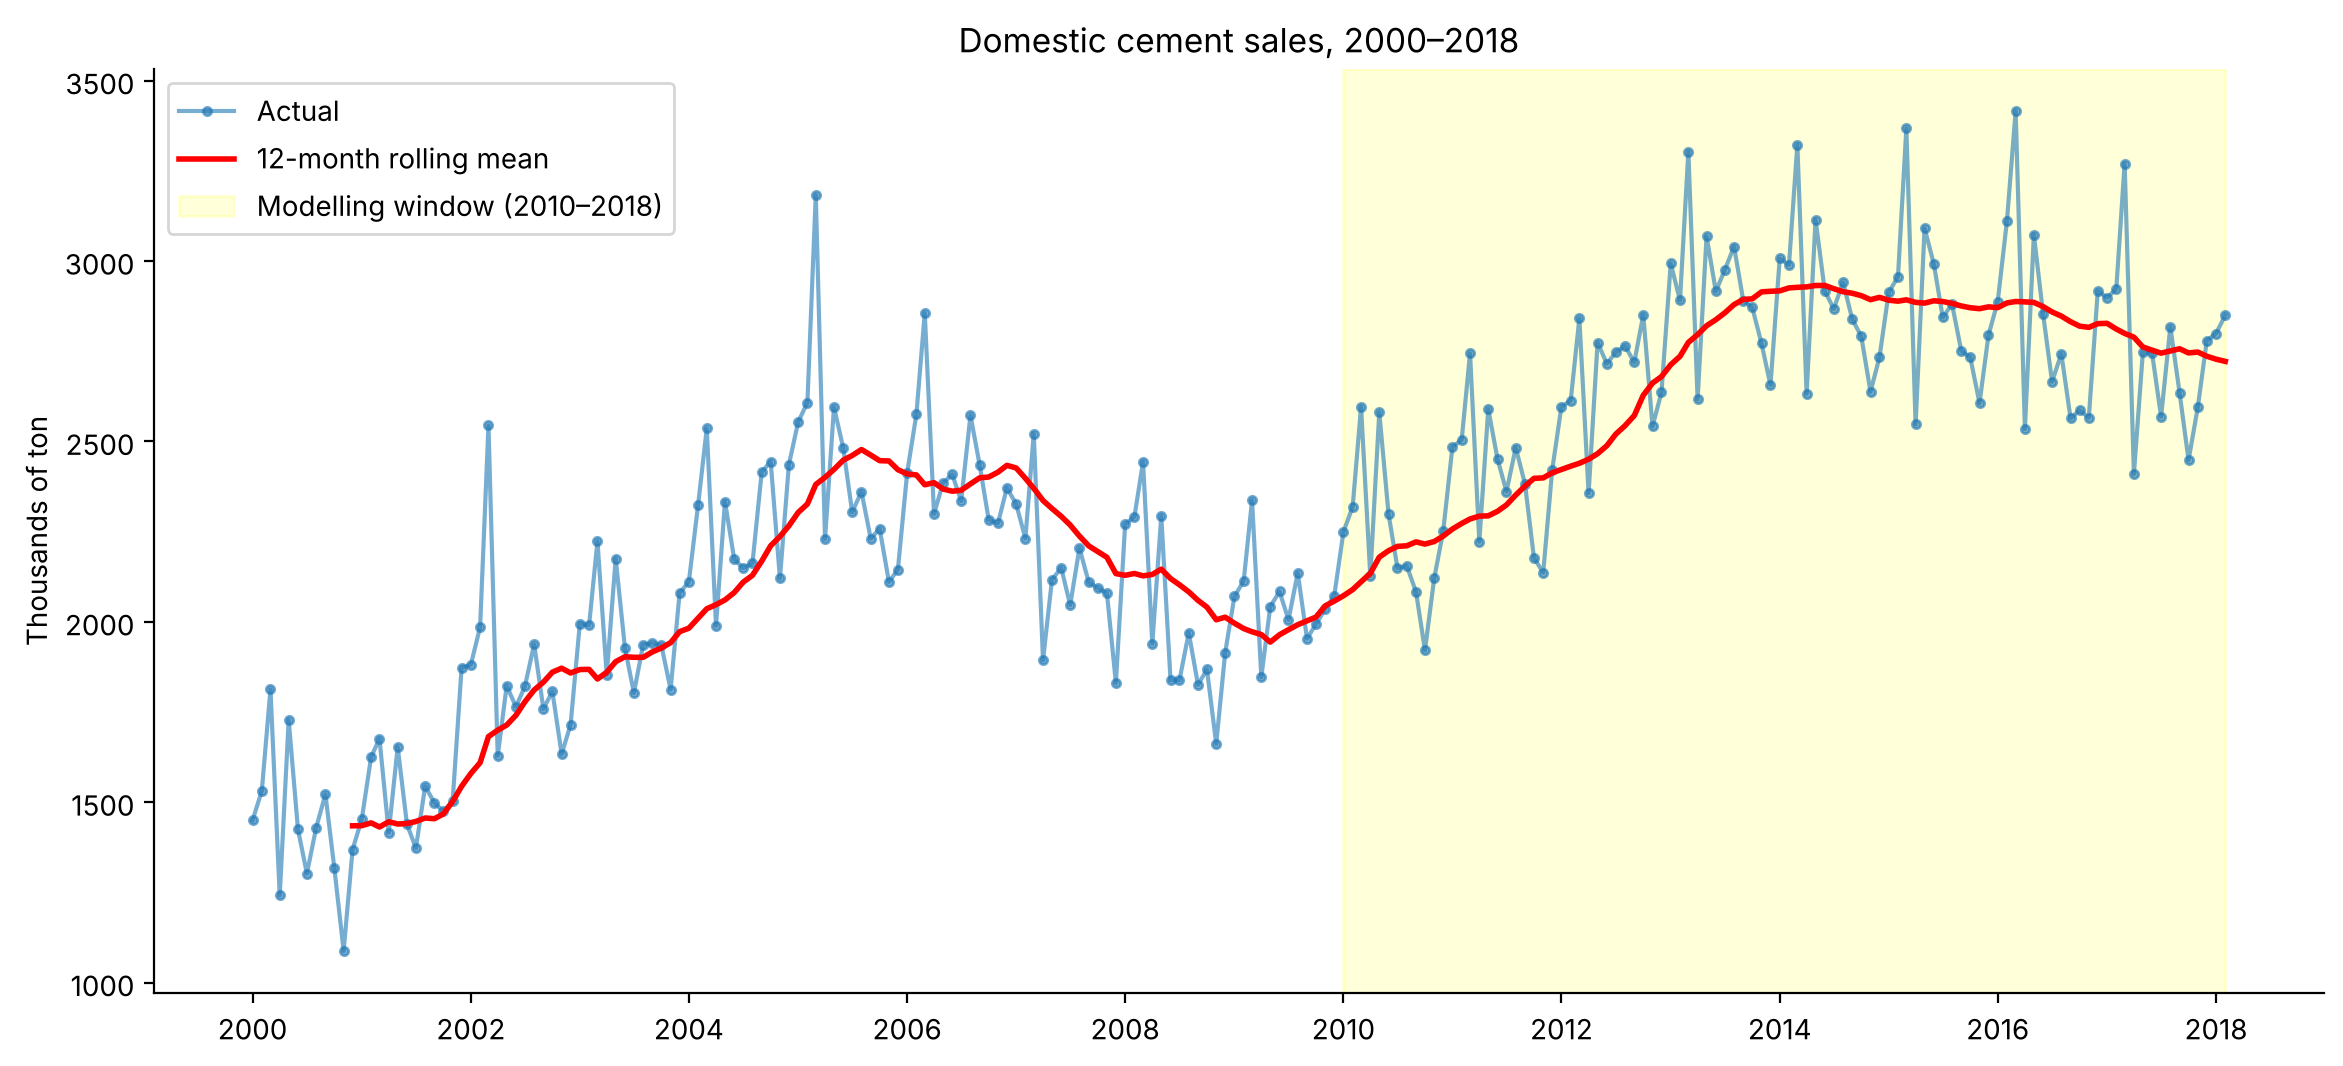

In [7]:
cement_full = investment_wide[TARGET].dropna()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(cement_full, marker="o", markersize=3, alpha=0.6, label="Actual")
ax.plot(cement_full.rolling(12).mean(), color="red", linewidth=2, label="12-month rolling mean")
ax.axvspan(pd.Timestamp("2010-01-01"), cement_full.index.max(), color="yellow", alpha=0.15,
           label="Modelling window (2010–2018)")
ax.set(title="Domestic cement sales, 2000–2018", ylabel="Thousands of ton")
ax.legend()
plt.show()

Cement sales grew strongly from 2000 to around 2007, dipped during the 2008–2009 global financial crisis, then recovered steadily to around 2014. From 2014 onward, sales plateaued at roughly 2.8–2.9 million tons per month.

This study models **2010–2018**: the post-crisis recovery and plateau. The BOT series ends in February 2018.

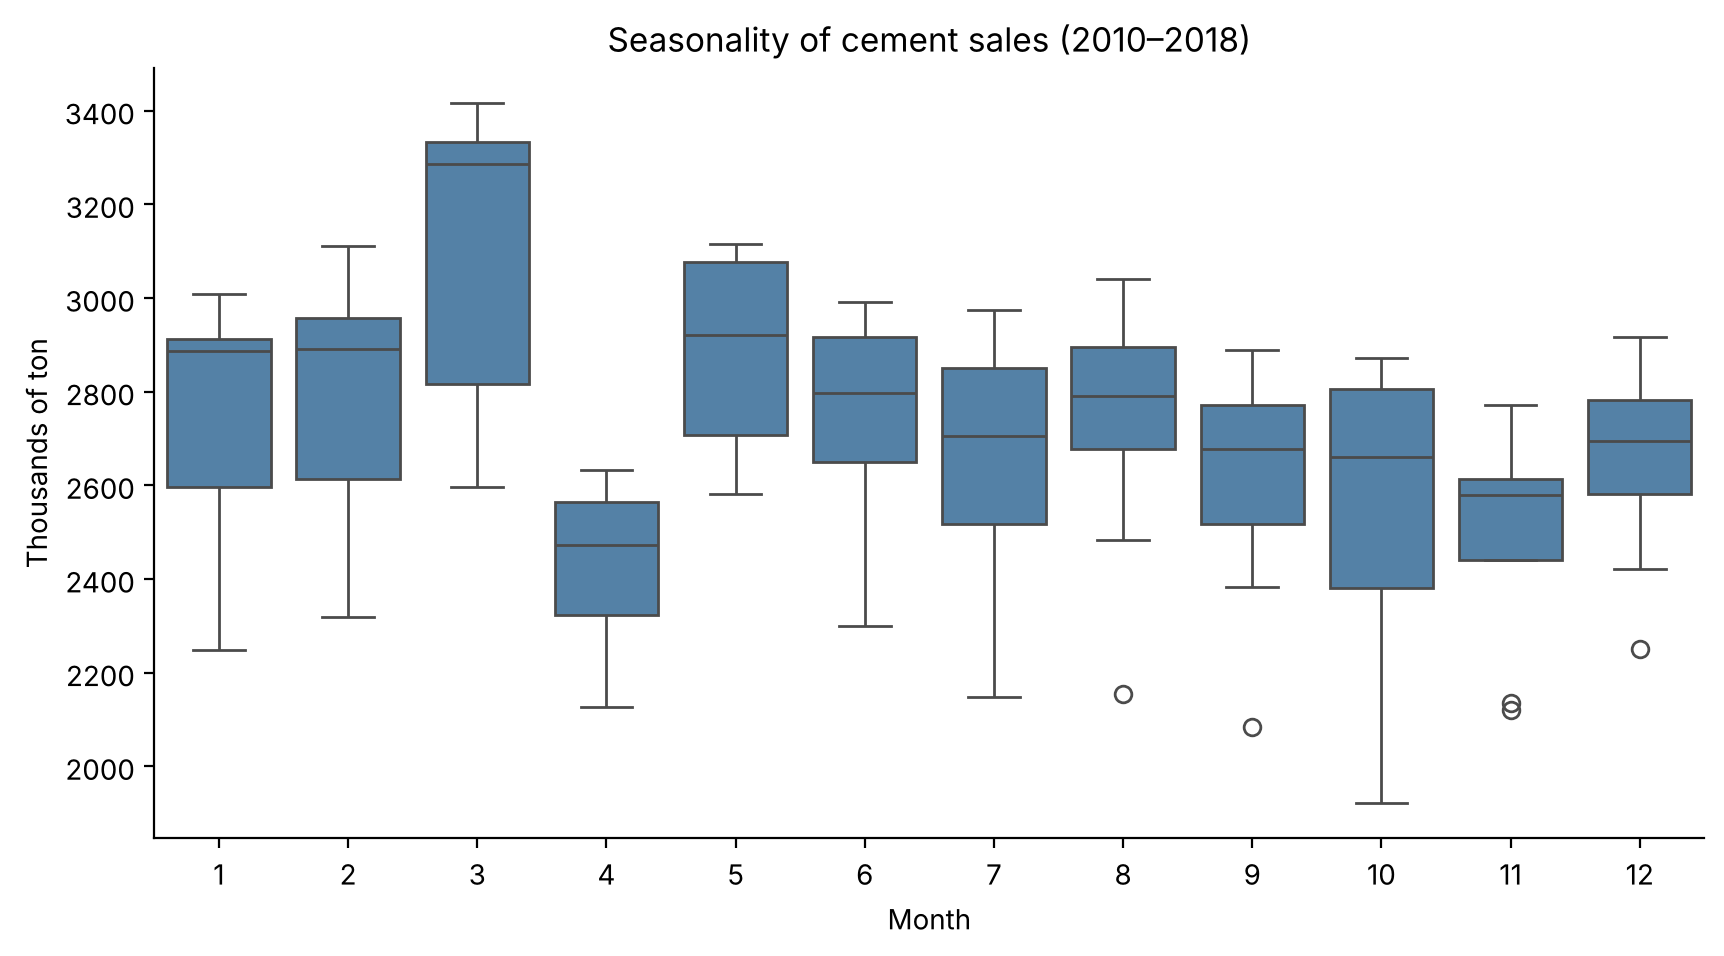

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x=df.index.month, y=df[TARGET], ax=ax, color="steelblue")
ax.set(title="Seasonality of cement sales (2010–2018)", xlabel="Month", ylabel="Thousands of ton")
plt.show()

Sales peak in **March** and drop sharply in **April**, consistent with reduced construction activity during the Songkran holiday. Demand then stabilises with moderate variation. Monthly seasonality must be part of every model.

## Decomposition and stationarity

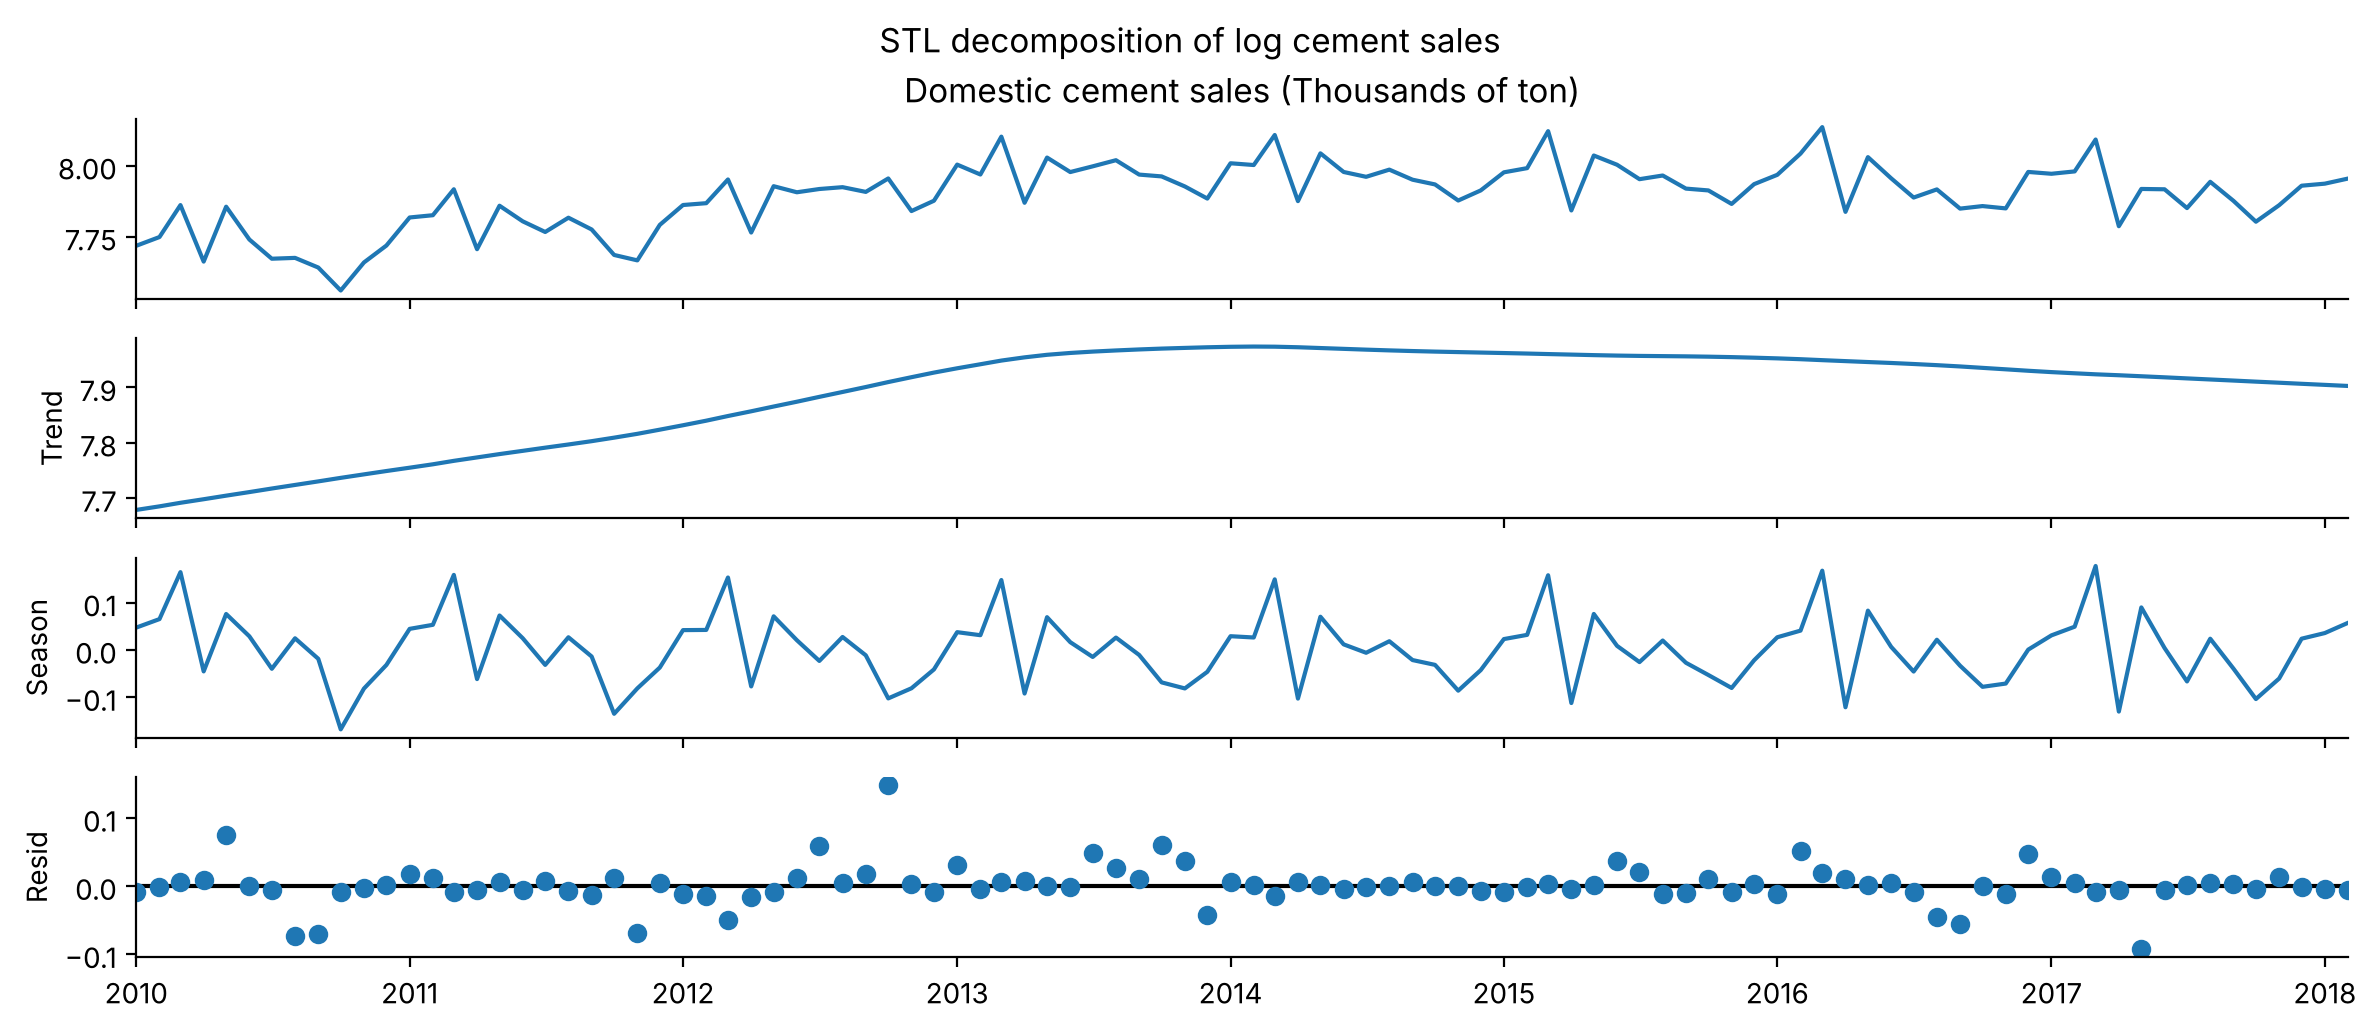

In [9]:
cement_log = np.log(df[TARGET])
stl = STL(cement_log, period=12, robust=True).fit()
stl.plot()
plt.suptitle("STL decomposition of log cement sales", y=1.02)
plt.show()

A log transformation stabilises the variance (seasonal swings grow with the level). STL (Seasonal-Trend decomposition using LOESS) is used rather than classical decomposition because it is robust to outliers.

In [10]:
adf = pd.DataFrame({
    "Series": ["log sales", "Δ log sales (first difference)", "Δ₁₂ log sales (seasonal difference)",
               "Δ Δ₁₂ log sales (both)"],
    "ADF statistic": [adfuller(s.dropna())[0] for s in
                      [cement_log, cement_log.diff(), cement_log.diff(12), cement_log.diff().diff(12)]],
    "p-value": [adfuller(s.dropna())[1] for s in
                [cement_log, cement_log.diff(), cement_log.diff(12), cement_log.diff().diff(12)]],
}).round(4)
adf

,Series,ADF statistic,p-value
0,log sales,-2.3770,0.1483
1,Δ log sales (first difference),-2.0568,0.2622
2,Δ₁₂ log sales (seasonal difference),-1.7773,0.3918
3,Δ Δ₁₂ log sales (both),-9.3333,0.0000


Log sales are non-stationary. After first **and** seasonal differencing (d = 1, D = 1), the series is clearly stationary. This matches the SARIMA specification below.

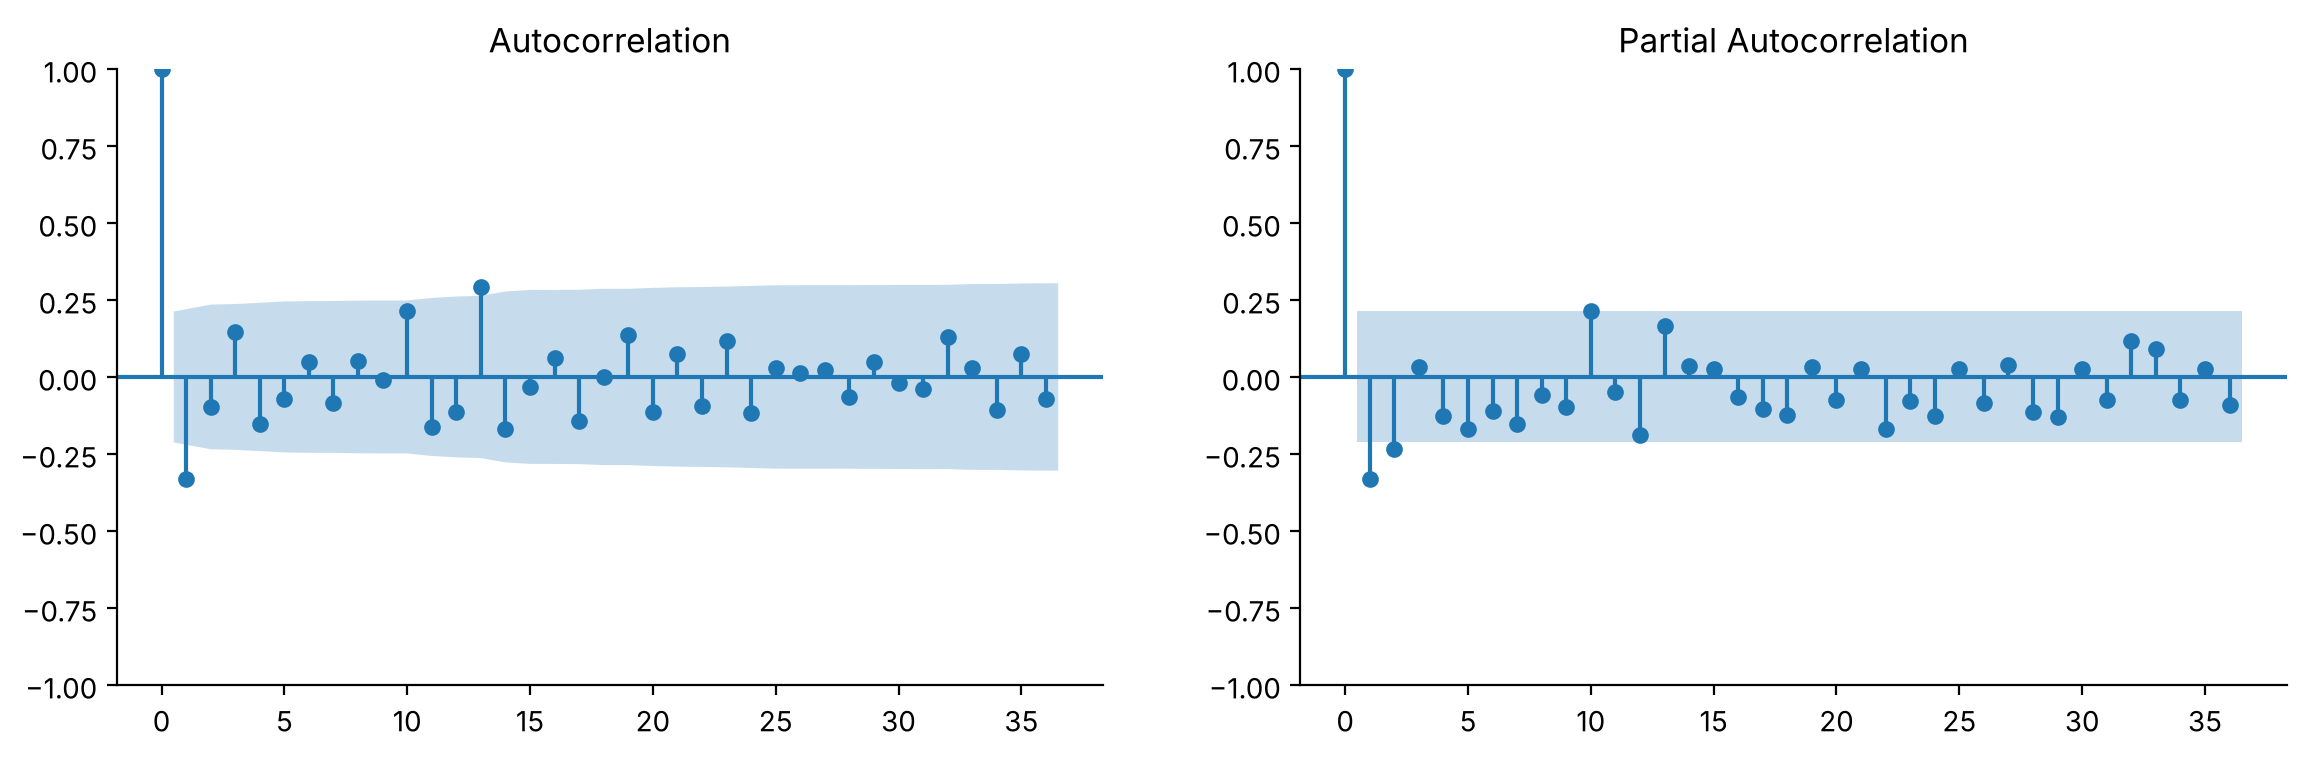

In [11]:
y_diff = cement_log.diff().diff(12).dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y_diff, lags=36, ax=axes[0])
plot_pacf(y_diff, lags=36, ax=axes[1])
plt.show()

After both differences, the ACF has a significant negative spike at **lag 1** and at **lag 12**, with little else.
This is the classic signature of the **airline model SARIMA(0,1,1)(0,1,1)₁₂**: one non-seasonal MA term and
one seasonal MA term.

## Which indicators lead cement demand?

Correlating raw levels of two trending series always looks strong (spurious correlation). Instead, the
cross-correlation below compares **year-over-year log growth**: cement at month *t* against each indicator at
*t − lead*.

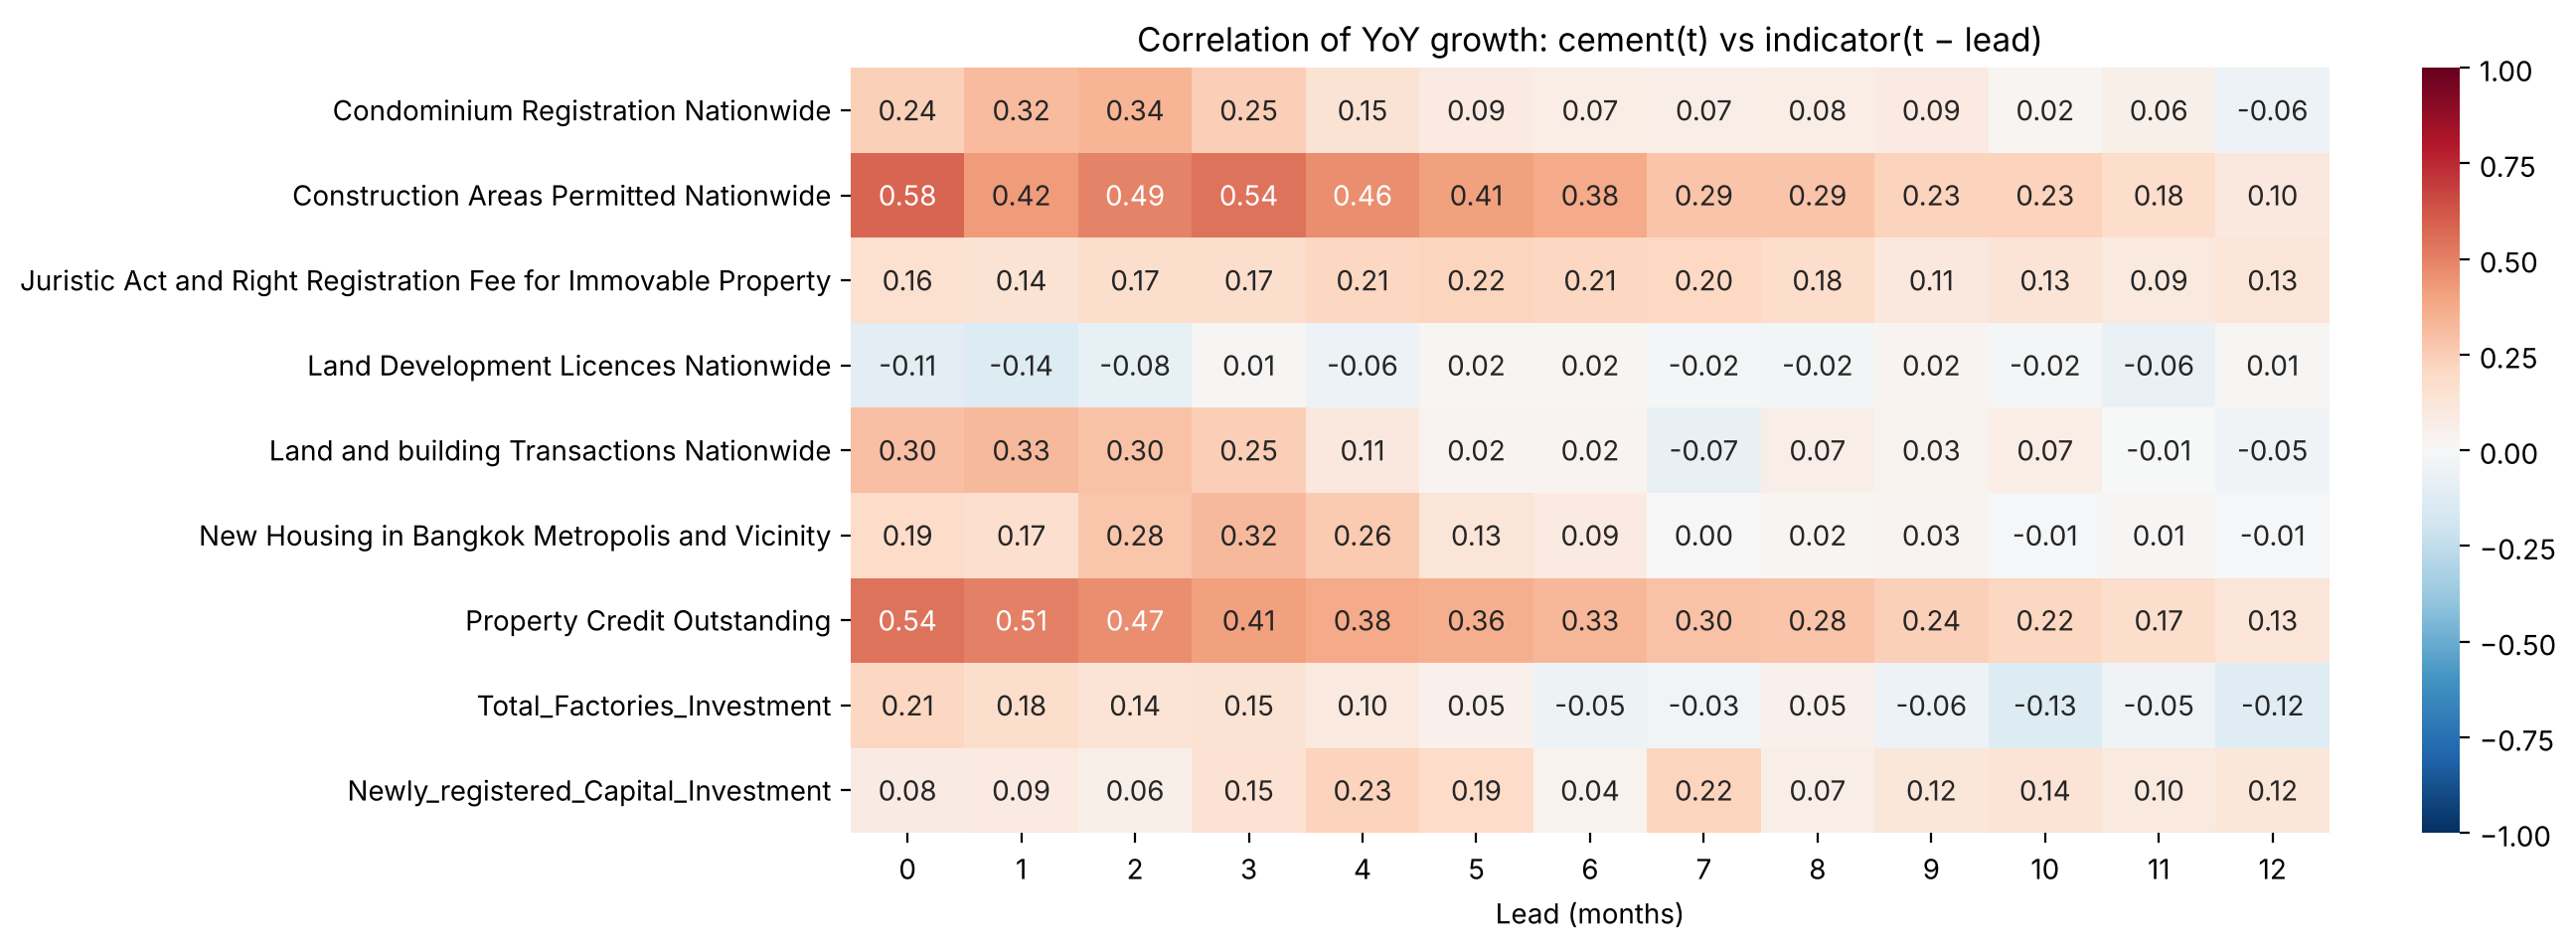

In [12]:
drivers = PROPERTY_FEATURES + ["Total_Factories_Investment", "Newly_registered_Capital_Investment"]
y_yoy = np.log(df[TARGET]).diff(12)

ccf_rows = {}
for col in drivers:
    x_yoy = np.log(df[col].clip(lower=1)).diff(12)
    pair = pd.concat([y_yoy, x_yoy], axis=1).dropna()
    # ccf(y, x)[k] = corr(y_t, x_{t-k}): the indicator leads by k months
    ccf_rows[col.split(" (")[0]] = ccf(pair.iloc[:, 0], pair.iloc[:, 1], adjusted=False)[:13]
ccf_df = pd.DataFrame(ccf_rows, index=pd.Index(range(13), name="Lead (months)")).T

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(ccf_df, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax)
ax.set_title("Correlation of YoY growth: cement(t) vs indicator(t − lead)")
plt.show()

**Construction Areas Permitted** and **Property Credit Outstanding** have the strongest leading relationship
with cement demand, followed by **Condominium Registration**. This fits the construction cycle:
permit issued → financing arranged → groundbreaking → structural work (heavy cement use).

These three are used as leading indicators in SARIMAX and XGBoost. Land Development Licences show almost no
relationship and are excluded.

# Feature engineering and modelling

**Leakage control.** At a forecast horizon *h*, an indicator is only usable if it was already published when the
forecast is made. Every exogenous feature is therefore lagged by *h* months.

**XGBoost design.** Tree models cannot extrapolate beyond the range seen in training, so XGBoost predicts
**year-over-year log growth** rather than the level. The forecast is then rebuilt as
`log ŷ(t+k) = log y(t+k−12) + predicted growth`. A separate model is trained for each step *k* = 1…*h*
(direct multi-horizon strategy), so it never feeds its own predictions back in.

In [13]:
EXOG = [
    "Construction Areas Permitted Nationwide (Thousand sq. metres)",
    "Property Credit Outstanding (Millions of Baht)",
    "Condominium Registration Nationwide (unit)",
]


def seasonal_naive(y_log, origin, h):
    steps = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    return pd.Series([y_log[s - pd.DateOffset(years=1)] for s in steps], index=steps)


def sarima(y_log, origin, h, X=None):
    """Airline model; X (if given) must already be lagged by >= h months."""
    res = SARIMAX(y_log[:origin], exog=None if X is None else X[:origin],
                  order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    steps = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    fc = res.get_forecast(h, exog=None if X is None else X.loc[steps])
    return fc.predicted_mean.set_axis(steps)


def xgb_direct(y_log, origin, h, X):
    """One XGBoost model per step k: features at t predict YoY log growth at t+k."""
    growth = y_log.diff(12)
    feats = pd.DataFrame({f"g_lag{l}": growth.shift(l) for l in [0, 1, 2, 3, 6, 11]}).join(X)
    preds, importances = {}, []
    for k in range(1, h + 1):
        data = feats.join(growth.shift(-k).rename("target"))
        data["month_k"] = ((data.index.month + k - 1) % 12) + 1  # calendar month being forecast
        train = data[:origin].iloc[:-k].dropna()  # target at t+k must be <= origin
        model = XGBRegressor(n_estimators=300, max_depth=2, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8, random_state=42)
        model.fit(train.drop(columns="target"), train["target"])
        x_now = data.loc[[origin]].drop(columns="target")
        step = origin + pd.DateOffset(months=k)
        preds[step] = y_log[step - pd.DateOffset(years=1)] + model.predict(x_now)[0]
        importances.append(pd.Series(model.feature_importances_, index=x_now.columns))
    return pd.Series(preds), pd.concat(importances, axis=1).mean(axis=1)

## Rolling-origin backtest

In [14]:
def run_backtest(df, exog_cols, h, n_origins):
    y_log = np.log(df[TARGET])
    X_log = np.log(df[exog_cols].clip(lower=1))
    short = lambda c: c.split(" (")[0]
    X_sarimax = X_log.shift(h).rename(columns=lambda c: f"{short(c)} (t-{h})").dropna()
    X_xgb = X_log.diff(12).shift(h).rename(columns=lambda c: f"{short(c)} YoY (t-{h})")
    y_sx = y_log[X_sarimax.index]

    origins = pd.date_range(end=y_log.index[-1] - pd.DateOffset(months=h), periods=n_origins, freq="MS")
    rows, importances = [], []
    for o in origins:
        xgb_fc, imp = xgb_direct(y_log, o, h, X_xgb)
        importances.append(imp)
        forecasts = {
            "Seasonal naive": seasonal_naive(y_log, o, h),
            "SARIMA": sarima(y_log, o, h),
            "SARIMAX": sarima(y_sx, o, h, X_sarimax),
            "XGBoost": xgb_fc,
        }
        for model, fc in forecasts.items():
            for k, (step, val) in enumerate(fc.items(), start=1):
                rows.append({"origin": o, "step": step, "k": k, "model": model,
                             "forecast": np.exp(val), "actual": np.exp(y_log[step])})
    bt = pd.DataFrame(rows)
    bt["abs_err"] = (bt["forecast"] - bt["actual"]).abs()
    bt["ape"] = bt["abs_err"] / bt["actual"] * 100
    return bt, pd.concat(importances, axis=1).mean(axis=1).sort_values(ascending=False)


def score(bt, df):
    mase_scale = df[TARGET].diff(12).abs().mean()  # MAE of the seasonal naive
    return (bt.groupby("model")
              .apply(lambda g: pd.Series({
                  "MAE": g["abs_err"].mean(),
                  "RMSE": np.sqrt(((g["forecast"] - g["actual"]) ** 2).mean()),
                  "MAPE (%)": g["ape"].mean(),
                  "MASE": g["abs_err"].mean() / mase_scale,
              }), include_groups=False)
              .sort_values("MAPE (%)").round(2))

### Main result: 3-month horizon, 24 forecast origins

In [15]:
H, N_ORIGINS = 3, 24
bt, importance = run_backtest(df, EXOG, H, N_ORIGINS)
scores = score(bt, df)
scores

,MAE,RMSE,MAPE (%),MASE
model,,,,
XGBoost,107.12,128.73,3.81,0.74
SARIMA,110.29,134.56,3.96,0.76
Seasonal naive,111.96,132.45,4.08,0.78
SARIMAX,131.06,157.41,4.72,0.91


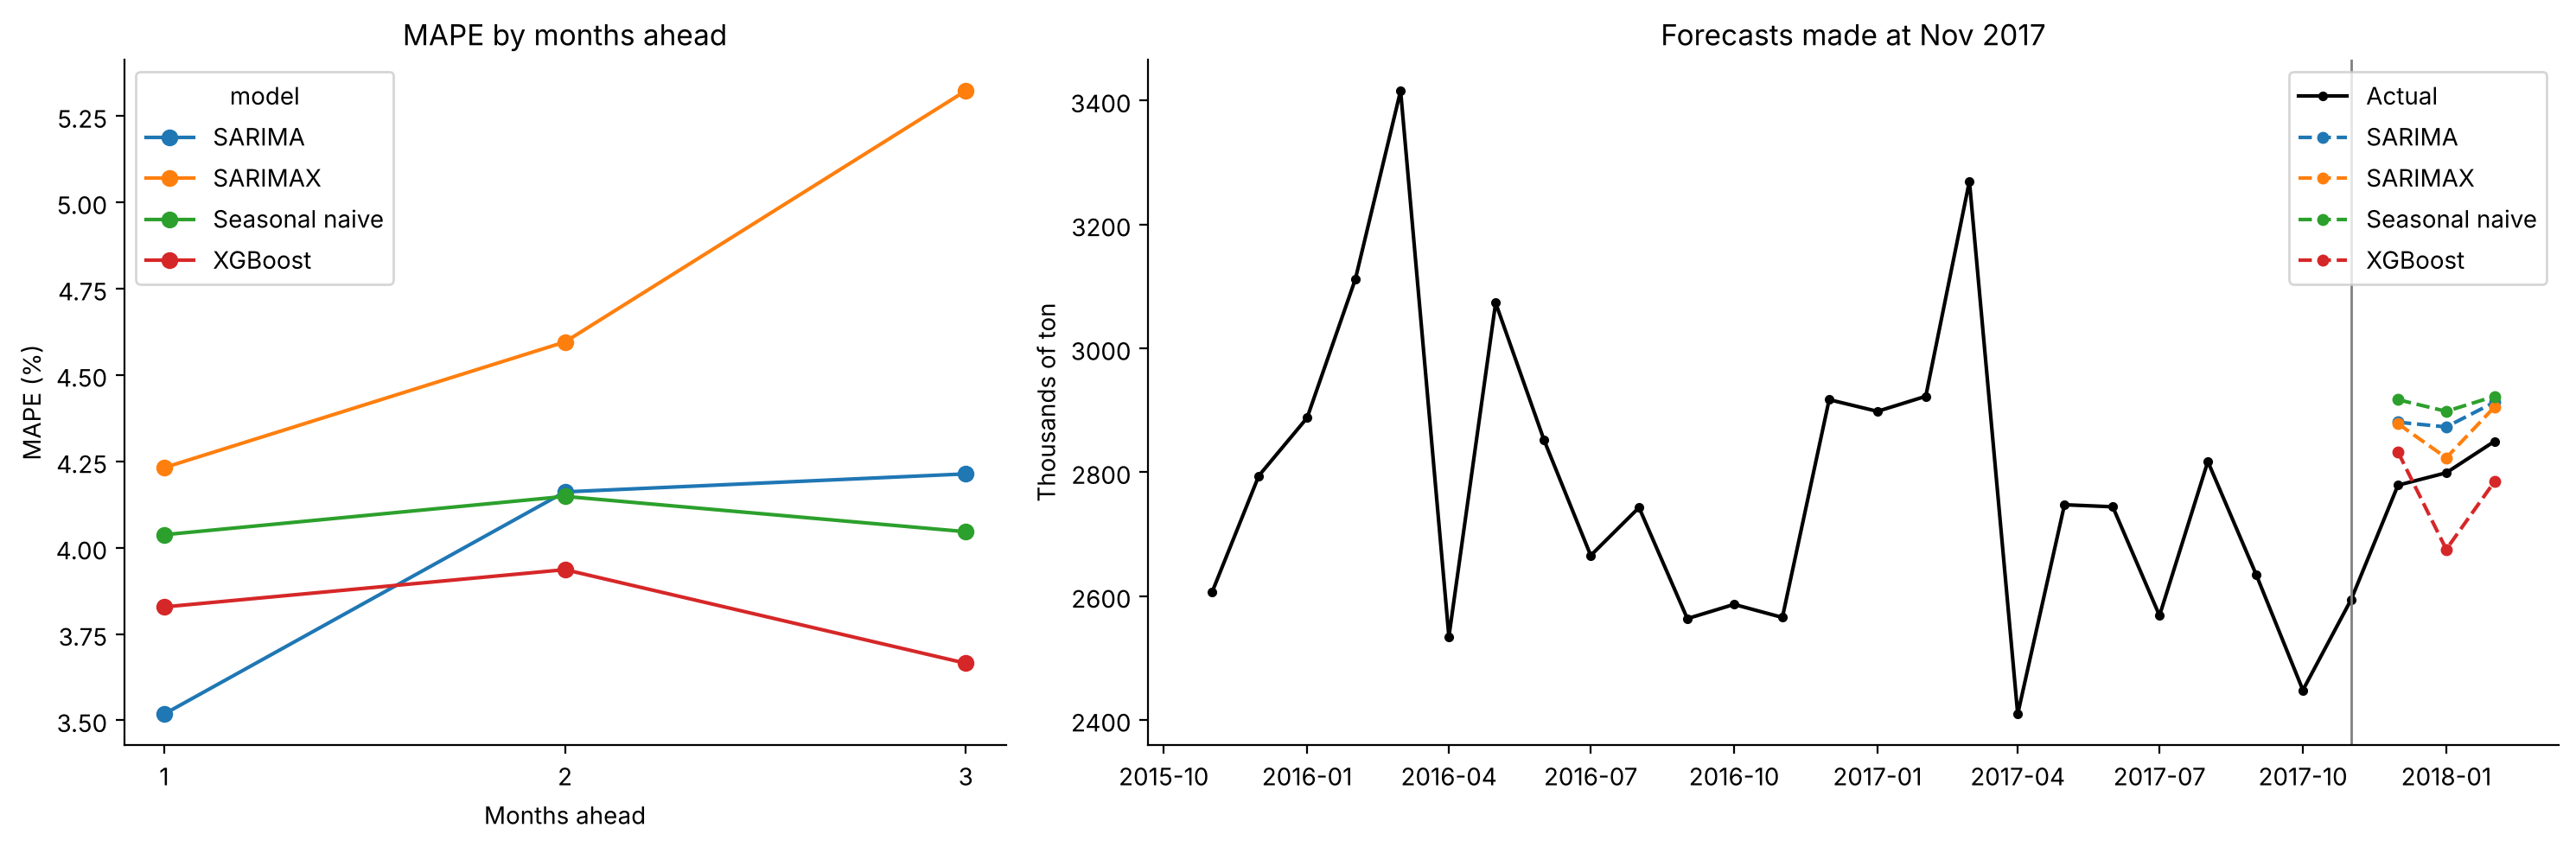

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.6]})

bt.groupby(["k", "model"])["ape"].mean().unstack().plot(marker="o", ax=axes[0])
axes[0].set(title="MAPE by months ahead", xlabel="Months ahead", ylabel="MAPE (%)", xticks=range(1, H + 1))

last_origin = bt["origin"].max()
hist = df[TARGET][last_origin - pd.DateOffset(months=24):]
axes[1].plot(hist, color="black", marker="o", markersize=3, label="Actual")
for model, g in bt[bt["origin"] == last_origin].groupby("model"):
    axes[1].plot(g["step"], g["forecast"], "--o", markersize=4, label=model)
axes[1].axvline(last_origin, color="gray", linewidth=1)
axes[1].set(title=f"Forecasts made at {last_origin:%b %Y}", ylabel="Thousands of ton")
axes[1].legend()
plt.tight_layout()
plt.show()

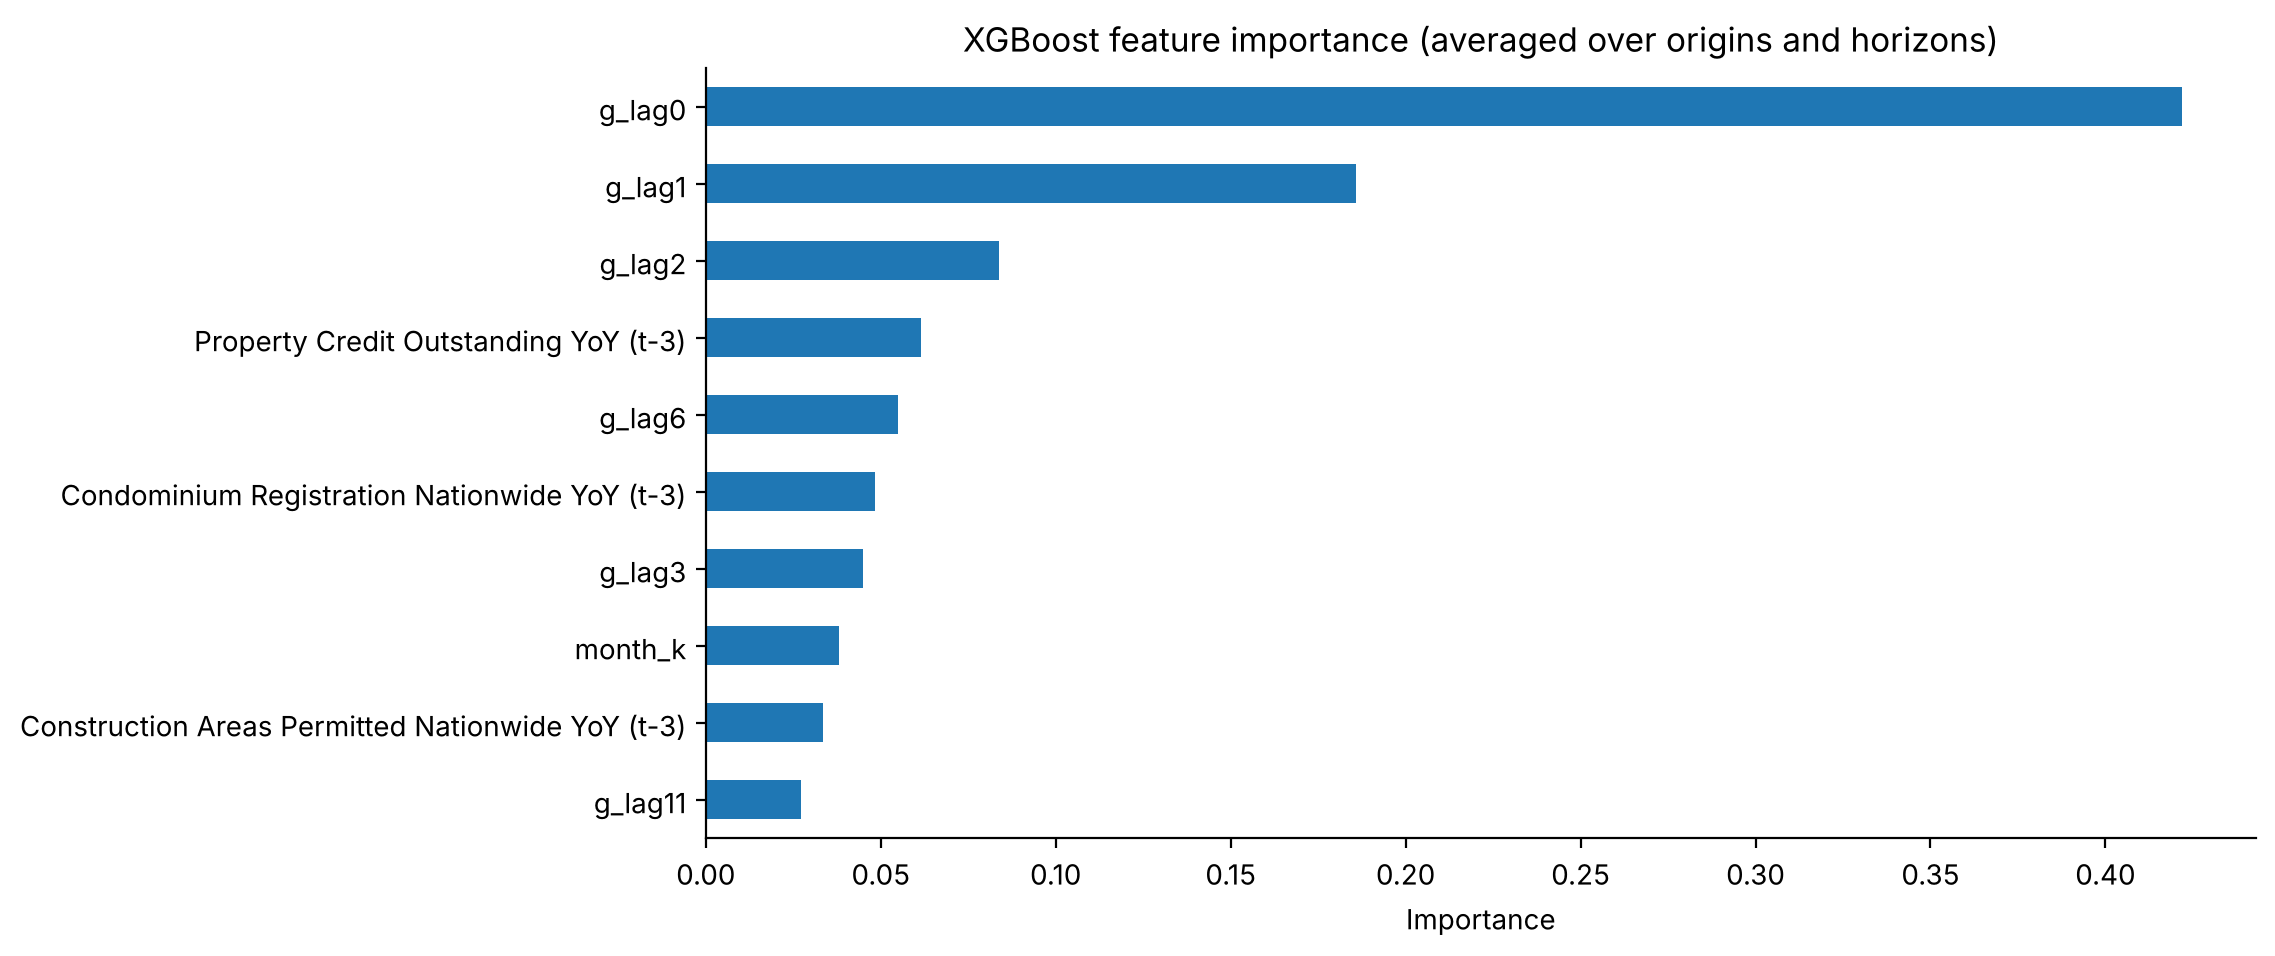

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
importance.head(12).sort_values().plot.barh(ax=ax)
ax.set(title="XGBoost feature importance (averaged over origins and horizons)", xlabel="Importance")
plt.show()

Recent year-over-year growth (`g_lag0`–`g_lag3`) dominates XGBoost. Among the macro indicators,
**Property Credit Outstanding** and **Condominium Registration** contribute most.

## Robustness check: does the ranking hold across horizons?

A ranking from one horizon can be noise. Every model is re-run at 1, 3 and 6 months ahead.

In [18]:
robust = {}
for h in (1, 3, 6):
    bt_h, _ = run_backtest(df, EXOG, h, N_ORIGINS)
    robust[f"h = {h}"] = bt_h.groupby("model")["ape"].mean()
robust = pd.DataFrame(robust).round(2).loc[["Seasonal naive", "SARIMA", "SARIMAX", "XGBoost"]]
display(robust.style.highlight_min(axis=0, color="#c6efce").format("{:.2f}"))

,h = 1,h = 3,h = 6
model,,,
Seasonal naive,4.05,4.08,3.98
SARIMA,3.25,3.96,4.25
SARIMAX,3.16,4.72,4.44
XGBoost,3.76,3.81,4.89


# Conclusion

In [19]:
best = scores.index[0]
naive = scores.loc["Seasonal naive", "MAPE (%)"]
print(f"3-month horizon: best model = {best}, MAPE {scores.loc[best, 'MAPE (%)']:.2f}% "
      f"vs seasonal naive {naive:.2f}% "
      f"({(1 - scores.loc[best, 'MAPE (%)'] / naive) * 100:.0f}% lower error)")
print(f"Average absolute error: {scores.loc[best, 'MAE']:,.0f} thousand tons per month")
print("\nBest model per horizon:")
print(robust.idxmin().to_string())

3-month horizon: best model = XGBoost, MAPE 3.81% vs seasonal naive 4.08% (7% lower error)
Average absolute error: 107 thousand tons per month

Best model per horizon:
h = 1           SARIMAX
h = 3           XGBoost
h = 6    Seasonal naive


**Findings**

- **1 month ahead:** SARIMAX and SARIMA are best (~3.2% MAPE). The leading indicators add a small improvement.
- **3 months ahead:** XGBoost is narrowly best (~3.8%), only slightly ahead of SARIMA and the seasonal naive.
- **6 months ahead:** no model beats the seasonal naive (~4.0%).
- **Overall:** in 2010–2018, Thai cement demand is dominated by a stable seasonal pattern on a flat plateau.
  The models' gains are small and real only up to about 3 months. Choose the model per horizon, and keep the
  seasonal naive as the fallback. A Diebold–Mariano test would show whether the differences are statistically significant.

**Business translation.** At ~2,800 thousand tons per month, each percentage point of MAPE is ≈28 thousand tons of
over- or under-production per month. The average absolute error (≈100 thousand tons) sets the minimum buffer
capacity or safety stock that production planning has to carry.

# Limitation

- **Regime changes.** The models assume relationships stay stable over time. Structural shocks such as the
  COVID-19 pandemic in 2020 break historical patterns. SARIMA/SARIMAX are most exposed. XGBoost is more flexible
  but still cannot anticipate unprecedented shifts.
- **Short history.** Eight years of monthly data (98 observations) is small for machine learning, so XGBoost is
  deliberately constrained (depth 2).
- **Data revisions.** BOT revises indicators after first release (`r` flags). The backtest uses final values,
  so live accuracy would be somewhat worse.
- **Discontinued source.** EC_EI_016_S2 ends in February 2018, so the model cannot be validated on recent years.

# Additional info (Appendix)

**Comparison between the Construction Material Sales Index and domestic cement sales**

Description from BOT: the construction material sales index includes sales of cement (portland, mixed, and
various types), clinkers, ready-mixed concrete, concrete piles, concrete floor planks, bricks, cement pipes,
sanitary fixtures, wall/floor tiles, asbestos cement roman roofing tile, and roofing tile.

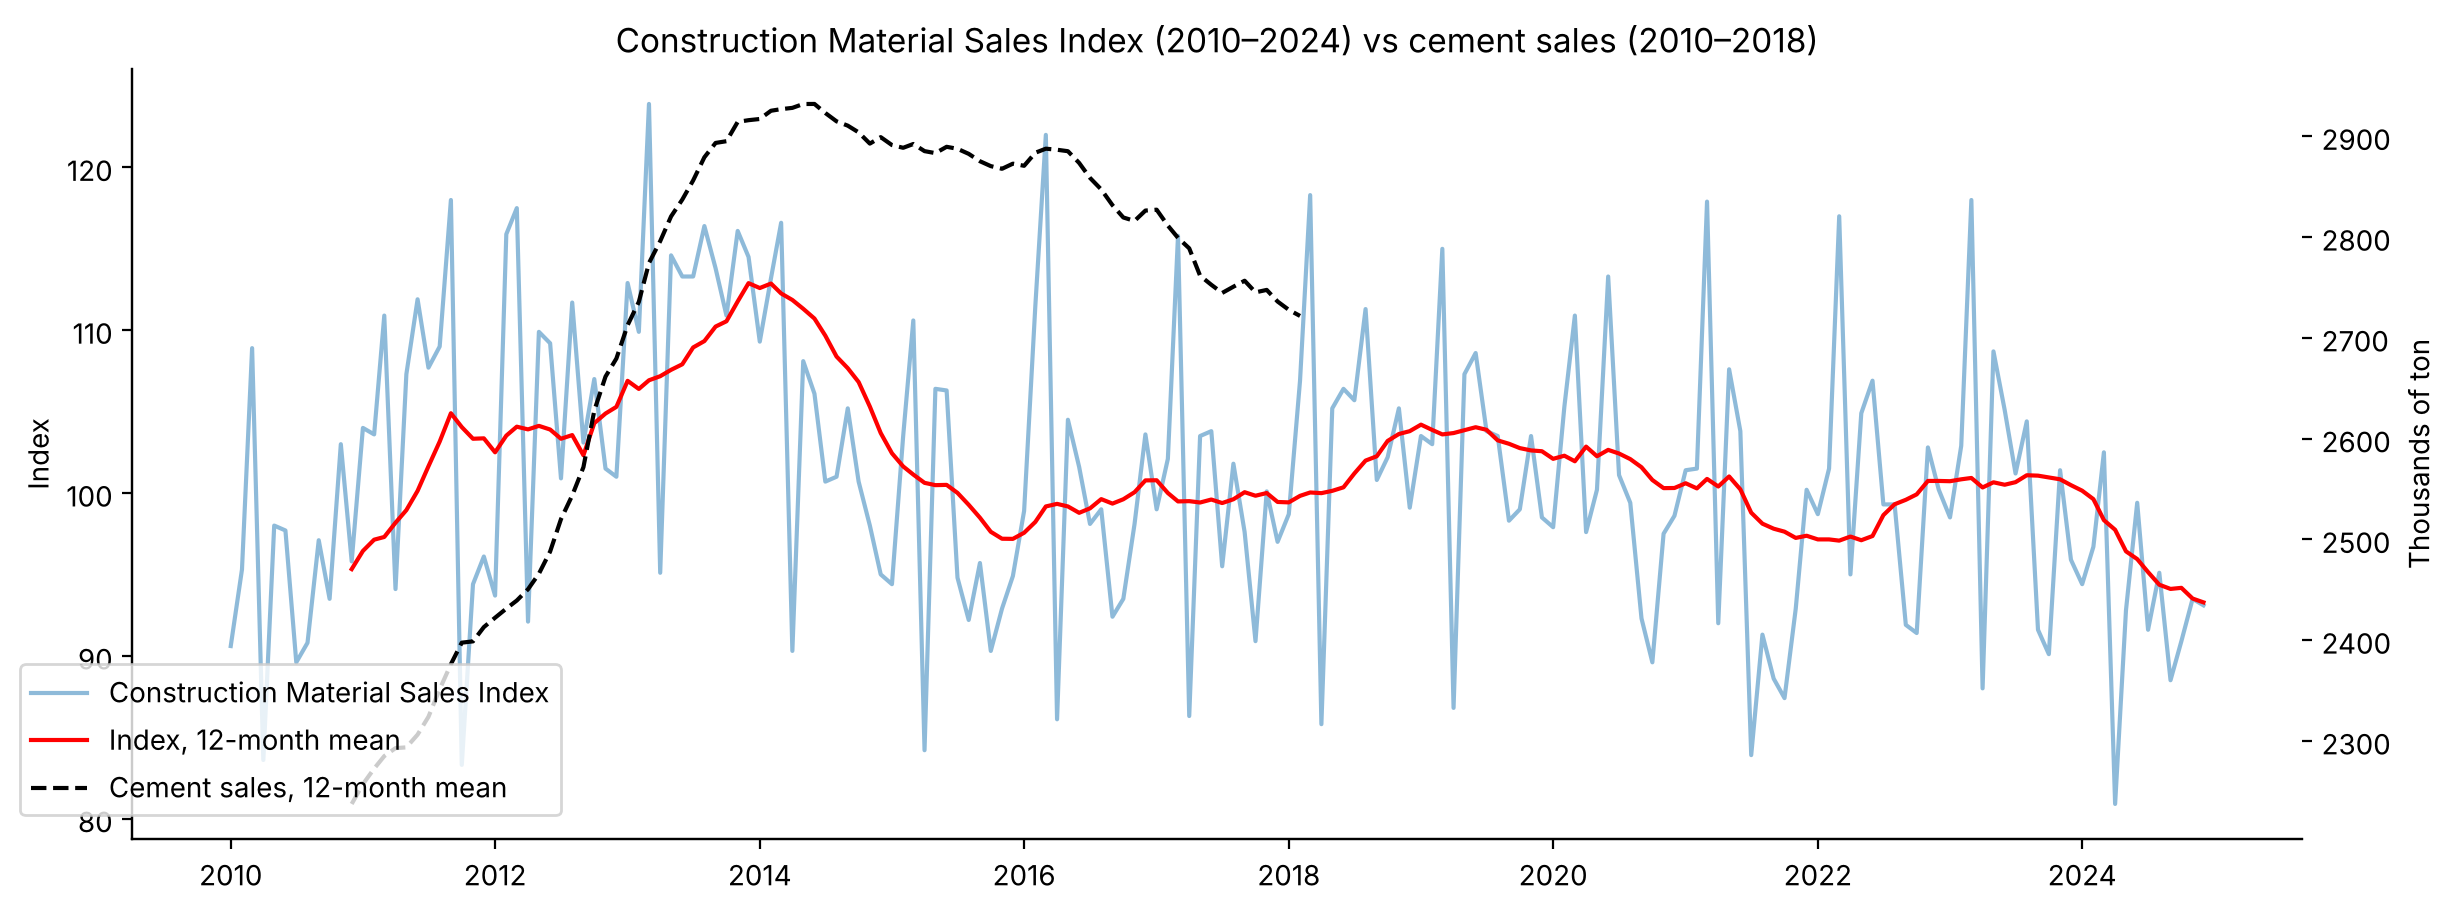

Correlation over the overlap (2010–2018): 0.61


In [20]:
construc = to_wide(pii_long, ["Private Investment Index (PII) > Construction Material Sales Index"]).iloc[:, 0]

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(construc, alpha=0.5, label="Construction Material Sales Index")
ax1.plot(construc.rolling(12).mean(), color="red", label="Index, 12-month mean")
ax1.set_ylabel("Index")
ax2 = ax1.twinx()
ax2.plot(cement_full["2010":].rolling(12).mean(), color="black", linestyle="--",
         label="Cement sales, 12-month mean")
ax2.set_ylabel("Thousands of ton")
fig.legend(loc="lower left", bbox_to_anchor=(0.08, 0.12))
ax1.set_title("Construction Material Sales Index (2010–2024) vs cement sales (2010–2018)")
plt.show()

overlap = pd.concat([construc, cement_full], axis=1).dropna()
print(f"Correlation over the overlap (2010–2018): {overlap.corr().iloc[0, 1]:.2f}")

The two series rise together until 2014 (correlation 0.61 over the overlap). After that they diverge: the index falls
back to ~100 while cement sales hold near 2.8 million tons, because the index also covers tiles, bricks and other
materials. The index extends to 2024, including the COVID-19 shock, so the **next project** is to apply the same
pipeline to it and test how the models behave across a structural break.